# Computer Vision Age Estimation

**Patrick Felder | TripleTen coursework**

Implemented data exploration and ResNet50 age-regression training functions. **The displayed training log is course-provided reference output, not a verified execution of my model.** No personally achieved MAE is claimed.

Place authorized face data in `data/faces/` or set `FACE_DATA_DIR`. The image dataset and pretrained weights are not included.


## Initialization

## Load Data

The dataset contains `labels.csv` with `file_name` and `real_age` columns and a `final_files/` directory of images. Images are loaded in batches.


In [1]:
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing.image import ImageDataGenerator

DATA_DIR = Path(os.environ.get('FACE_DATA_DIR', 'data/faces'))
if not DATA_DIR.exists() and Path('/datasets/faces').exists():
    DATA_DIR = Path('/datasets/faces')
labels = pd.read_csv(DATA_DIR / 'labels.csv')

display(labels.head())
display(labels.info())
display(labels.describe())

print('Dataset shape:', labels.shape)
print('Number of images:', len(labels))
print('Number of unique image files:', labels['file_name'].nunique())
print('Missing values:')
print(labels.isna().sum())
print('Duplicated rows:', labels.duplicated().sum())

print('Minimum age:', labels['real_age'].min())
print('Maximum age:', labels['real_age'].max())
print('Average age:', labels['real_age'].mean())
print('Median age:', labels['real_age'].median())

,file_name,real_age
0,000000.jpg,4
1,000001.jpg,18
2,000002.jpg,80
3,000003.jpg,50
4,000004.jpg,17


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7591 entries, 0 to 7590
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   file_name  7591 non-null   object
 1   real_age   7591 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 118.7+ KB


None

,real_age
count,7591.000000
mean,31.201159
std,17.145060
min,1.000000
25%,20.000000
50%,29.000000
75%,41.000000
max,100.000000


Dataset shape: (7591, 2)
Number of images: 7591
Number of unique image files: 7591
Missing values:
file_name    0
real_age     0
dtype: int64
Duplicated rows: 0
Minimum age: 1
Maximum age: 100
Average age: 31.20115926755368
Median age: 29.0


## EDA

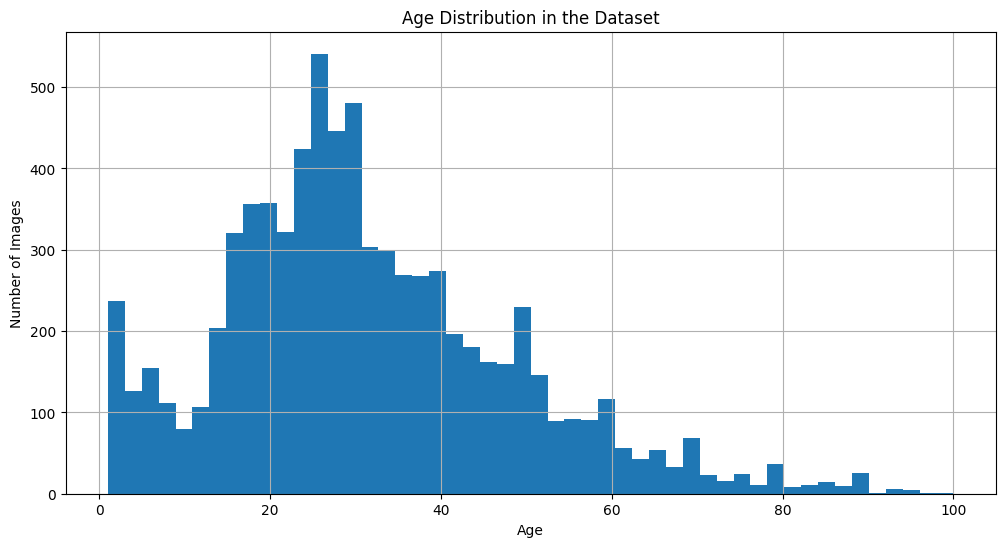

Found 7591 validated image filenames.


In [2]:
plt.figure(figsize=(12, 6))

labels['real_age'].hist(bins=50)

plt.title('Age Distribution in the Dataset')
plt.xlabel('Age')
plt.ylabel('Number of Images')
plt.show()
datagen = ImageDataGenerator(rescale=1./255)

generator = datagen.flow_from_dataframe(
    dataframe=labels,
    directory=str(DATA_DIR / 'final_files'),
    x_col='file_name',
    y_col='real_age',
    target_size=(224, 224),
    batch_size=15,
    class_mode='raw',
    seed=12345
)

features, target = next(generator)

plt.figure(figsize=(12, 12))

for i in range(15):
    plt.subplot(5, 3, i + 1)
    plt.imshow(features[i])
    plt.title(f'Age: {target[i]}')
    plt.axis('off')

plt.tight_layout()
plt.show()

### Findings

The dataset contains 7,591 face images with real age labels. The labels file has two columns: `file_name` and `real_age`. Each row represents one image and its matching age label.

The target variable, `real_age`, is numerical, so this is a regression task. The model should predict one number: the estimated age.

The age distribution is uneven. Some age groups appear more often than others. This can affect model training because the model may learn to predict common age groups better than rare age groups.

This matters for Good Seed because the business goal depends on correctly identifying customers who may be underage. The model needs to be especially reliable for young customers and people close to the legal drinking age.

The sample images show differences in lighting, face angle, background, facial expression, and image quality. These differences make the project realistic, but they also make age prediction more difficult.

Because the dataset is moderately sized for deep learning, transfer learning with a pretrained convolutional neural network such as ResNet50 is appropriate.

## Modelling

In [3]:
from pathlib import Path
import pandas as pd

import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet import ResNet50
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.optimizers import Adam

In [4]:
def load_train(path):
    """
    It loads the train part of dataset from path
    """
    
    labels = pd.read_csv(Path(path) / 'labels.csv')
    
    train_datagen = ImageDataGenerator(
        validation_split=0.25,
        rescale=1./255,
        horizontal_flip=True
    )
    
    train_gen_flow = train_datagen.flow_from_dataframe(
        dataframe=labels,
        directory=str(Path(path) / 'final_files'),
        x_col='file_name',
        y_col='real_age',
        target_size=(224, 224),
        batch_size=32,
        class_mode='raw',
        subset='training',
        seed=12345
    )
    
    return train_gen_flow

In [5]:
def load_test(path):
    """
    It loads the validation part of dataset from path
    """
    
    labels = pd.read_csv(Path(path) / 'labels.csv')
    
    test_datagen = ImageDataGenerator(
        validation_split=0.25,
        rescale=1./255
    )
    
    test_gen_flow = test_datagen.flow_from_dataframe(
        dataframe=labels,
        directory=str(Path(path) / 'final_files'),
        x_col='file_name',
        y_col='real_age',
        target_size=(224, 224),
        batch_size=32,
        class_mode='raw',
        subset='validation',
        seed=12345
    )
    
    return test_gen_flow

In [6]:
def create_model(input_shape):
    """
    It defines the model
    """
    
    backbone = ResNet50(
        weights='imagenet',
        input_shape=input_shape,
        include_top=False
    )

    model = Sequential()
    model.add(backbone)
    model.add(GlobalAveragePooling2D())
    model.add(Dropout(0.2))
    model.add(Dense(1, activation='relu'))

    optimizer = Adam(learning_rate=0.0001)

    model.compile(
        optimizer=optimizer,
        loss='mse',
        metrics=['mae']
    )

    return model

In [7]:
def train_model(model, train_data, test_data, batch_size=None, epochs=20,
                steps_per_epoch=None, validation_steps=None):
    """
    Trains the model given the parameters
    """
    
    if steps_per_epoch is None:
        steps_per_epoch = len(train_data)
        
    if validation_steps is None:
        validation_steps = len(test_data)

    model.fit(
        train_data,
        validation_data=test_data,
        batch_size=batch_size,
        epochs=epochs,
        steps_per_epoch=steps_per_epoch,
        validation_steps=validation_steps,
        verbose=2
    )

    return model

### Portable training script

The equivalent model functions are included in `train_model.py`, which accepts a dataset path and saves the final model from a new run. This script has not been trained during packaging.


### Course-provided reference training log

The following log was supplied by the course and analyzed in the original submission. It is not evidence of my own GPU run.


Epoch 1/20
356/356 - 35s - loss: 95.3532 - mae: 7.4339 - val_loss: 124.3362 - val_mae: 8.4921
Epoch 2/20
356/356 - 35s - loss: 76.8372 - mae: 6.6707 - val_loss: 127.6357 - val_mae: 8.6035
Epoch 3/20
356/356 - 35s - loss: 69.9428 - mae: 6.3992 - val_loss: 91.1531 - val_mae: 7.4454
Epoch 4/20
356/356 - 35s - loss: 64.4249 - mae: 6.1407 - val_loss: 124.0287 - val_mae: 8.3481
Epoch 5/20
356/356 - 35s - loss: 52.8486 - mae: 5.5913 - val_loss: 109.1004 - val_mae: 8.2192
Epoch 6/20
356/356 - 35s - loss: 46.3094 - mae: 5.2223 - val_loss: 85.1038 - val_mae: 7.0332
Epoch 7/20
356/356 - 35s - loss: 38.2617 - mae: 4.7951 - val_loss: 92.0900 - val_mae: 7.3359
Epoch 8/20
356/356 - 35s - loss: 37.4804 - mae: 4.7402 - val_loss: 80.0016 - val_mae: 6.7239
Epoch 9/20
356/356 - 35s - loss: 33.5237 - mae: 4.4271 - val_loss: 83.2579 - val_mae: 6.8529
Epoch 10/20
356/356 - 35s - loss: 28.5170 - mae: 4.1411 - val_loss: 83.5056 - val_mae: 6.9629
Epoch 11/20
356/356 - 35s - loss: 27.0142 - mae: 3.9700 - val_loss: 92.1290 - val_mae: 7.1866
Epoch 12/20
356/356 - 35s - loss: 27.4564 - mae: 4.0428 - val_loss: 185.6307 - val_mae: 11.4591
Epoch 13/20
356/356 - 35s - loss: 23.7961 - mae: 3.7407 - val_loss: 92.3429 - val_mae: 7.2467
Epoch 14/20
356/356 - 35s - loss: 24.6167 - mae: 3.8116 - val_loss: 92.4542 - val_mae: 7.1401
Epoch 15/20
356/356 - 35s - loss: 22.2604 - mae: 3.6746 - val_loss: 82.5822 - val_mae: 6.7841
Epoch 16/20
356/356 - 35s - loss: 20.1899 - mae: 3.4430 - val_loss: 86.3830 - val_mae: 6.8304
Epoch 17/20
356/356 - 35s - loss: 17.3425 - mae: 3.2205 - val_loss: 78.4369 - val_mae: 6.6419
Epoch 18/20
356/356 - 35s - loss: 16.5249 - mae: 3.1295 - val_loss: 81.7731 - val_mae: 6.7226
Epoch 19/20
356/356 - 35s - loss: 16.6140 - mae: 3.1421 - val_loss: 80.9727 - val_mae: 6.9908
Epoch 20/20
356/356 - 35s - loss: 17.0187 - mae: 3.1785 - val_loss: 93.4115 - val_mae: 7.6512


The supplied reference log reports final validation MAE of 7.6512 years and best validation MAE of 6.6419 years at epoch 17. No separate test-set score or personally achieved training result is available.


## Conclusions

## Analysis of the reference results

The supplied log covers 20 epochs. Training MAE falls from 7.4339 to 3.1785 years. Best validation MAE is 6.6419 at epoch 17; final validation MAE is 7.6512 at epoch 20. These reference values are below the eight-year coursework target.

The training/validation gap and worsening validation MAE after the best epoch suggest overfitting. Early stopping and best-checkpoint saving would be sensible next experiments; they are not implemented in the original functions.

The reference log reports 356 steps per epoch. The supplied code's default 75% training subset and batch size 32 would imply approximately 178 steps for 7,591 images. This is another reason not to treat the reference log as a reproduced run of these functions.

An average age error is not sufficient evidence for real-world age-verification decisions. Performance around age thresholds and across age groups would require separate evaluation. No deployment or business outcome is claimed.
